# IMAES - Experiment 7
## Logical and Probabilistic Reasoning

**Aim:** To implement basic Propositional Logic, First-Order Logic, and probability-based reasoning using Python.

### Exercises
1. Propositional Logic - represent "If it rains, then the road is wet", generate its truth table, and verify the result.
2. First-Order Logic - represent "All humans are mortal" and "Socrates is a human", then derive whether Socrates is mortal.
3. Probability of Events - calculate individual, joint, and union probabilities from a student attendance/performance dataset.
4. Conditional Probability - calculate P(A|B) and P(B|A).
5. Bayes' Theorem - calculate the probability of disease after a positive diagnostic test.
6. Visualization - visualize calculated probabilities and observe the effect of changing an input probability.

## Theory

**Propositional Logic** represents facts as propositions that are either True or False. An implication P -> Q is false only when P is True and Q is False.

**First-Order Logic (FOL)** extends propositional logic with predicates, variables, quantifiers, and relations. The statement "All humans are mortal" can be written as forall x (Human(x) -> Mortal(x)). Together with Human(Socrates), it follows that Mortal(Socrates).

**Probability** measures uncertainty. For an event A, P(A) is the fraction of outcomes in which A occurs. Joint probability is P(A and B), and union probability is P(A or B).

**Conditional probability** measures the probability of one event when another event is known: P(A|B)=P(A and B)/P(B).

**Bayes' theorem** updates a prior probability after observing evidence: P(D|+) = P(+|D)P(D)/P(+).

## 1. Propositional Logic

In [1]:
import itertools
import pandas as pd

def implication(p, q):
    return (not p) or q

rows=[]
for rains, wet in itertools.product([False, True], repeat=2):
    rows.append({"Rains (P)":rains,"Road Wet (Q)":wet,"P -> Q":implication(rains,wet)})
truth_table=pd.DataFrame(rows)
truth_table

,Rains (P),Road Wet (Q),P -> Q
0,False,False,True
1,False,True,True
2,True,False,False
3,True,True,True


In [2]:
expected=[True,True,False,True]
verified=truth_table["P -> Q"].tolist()==expected
print("Truth table verified:",verified)
print("Rule: If it rains, then the road is wet.")

Truth table verified: True
Rule: If it rains, then the road is wet.


### Observation
The implication P -> Q is False only when it rains but the road is not wet. All other combinations satisfy the rule.

## 2. First-Order Logic

In [3]:
facts={"Human(Socrates)"}
rules=[("Human(x)","Mortal(x)")]

def derive_socrates_mortal(facts,rules):
    if "Human(Socrates)" in facts:
        for antecedent,consequent in rules:
            if antecedent=="Human(x)" and consequent=="Mortal(x)":
                return True,"Mortal(Socrates)"
    return False,None

derived,conclusion=derive_socrates_mortal(facts,rules)
print("Facts:")
for fact in facts: print(" ",fact)
print("Rule: Human(x) -> Mortal(x)")
print("Derived:",conclusion if derived else "No conclusion")

Facts:
  Human(Socrates)
Rule: Human(x) -> Mortal(x)
Derived: Mortal(Socrates)


### Observation
The universal rule applies to every individual satisfying Human(x). Since Human(Socrates) is a known fact, the program derives Mortal(Socrates).

## 3. Probability of Events

In [4]:
data=pd.DataFrame({
    "Student":[f"S{i}" for i in range(1,11)],
    "Passed":[1,1,1,1,1,0,0,0,1,0],
    "Attended":[1,1,1,0,1,0,1,0,0,0]
})
data

,Student,Passed,Attended
0,S1,1,1
1,S2,1,1
2,S3,1,1
3,S4,1,0
4,S5,1,1
5,S6,0,0
6,S7,0,1
7,S8,0,0
8,S9,1,0
9,S10,0,0


In [13]:
A=data["Passed"]==1
B=data["Attended"]==1
p_A=A.mean(); p_B=B.mean(); p_inter=(A&B).mean(); p_union=(A|B).mean()
print(f"P(Passed) = {p_A:.3f}")
print(f"P(Attended) = {p_B:.3f}")
print(f"P(Passed and Attended) = {p_inter:.3f}")
print(f"P(Passed or Attended) = {p_union:.3f}")
union_formula=p_A+p_B-p_inter
print(f"Union formula = {union_formula:.3f}")

P(Passed) = 0.600
P(Attended) = 0.500
P(Passed and Attended) = 0.400
P(Passed or Attended) = 0.700
Union formula = 0.700


### Observation
The event probabilities are computed directly from the ten observations. The union probability satisfies P(A or B)=P(A)+P(B)-P(A and B), confirming the inclusion-exclusion rule.

## 4. Conditional Probability

In [6]:
p_A_given_B=p_inter/p_B
p_B_given_A=p_inter/p_A
print(f"P(Passed | Attended) = {p_A_given_B:.3f}")
print(f"P(Attended | Passed) = {p_B_given_A:.3f}")

P(Passed | Attended) = 0.800
P(Attended | Passed) = 0.667


### Interpretation
P(Passed|Attended) answers the probability that a student passed given that the student attended. P(Attended|Passed) answers the probability that a student attended given that the student passed. These values are generally different because the conditioning event changes the denominator.

## 5. Bayes' Theorem - Disease Diagnosis

In [7]:
P_D=0.01
P_pos_given_D=0.95
P_pos_given_not_D=0.05
P_not_D=1-P_D
P_pos=P_pos_given_D*P_D+P_pos_given_not_D*P_not_D
P_D_given_pos=(P_pos_given_D*P_D)/P_pos
print(f"P(Disease) = {P_D:.3f}")
print(f"P(Positive | Disease) = {P_pos_given_D:.3f}")
print(f"P(Positive | No Disease) = {P_pos_given_not_D:.3f}")
print(f"P(Positive) = {P_pos:.3f}")
print(f"P(Disease | Positive) = {P_D_given_pos:.3f}")

P(Disease) = 0.010
P(Positive | Disease) = 0.950
P(Positive | No Disease) = 0.050
P(Positive) = 0.059
P(Disease | Positive) = 0.161


### Interpretation
Although the test has high sensitivity, disease prevalence is low. Therefore, a positive result does not mean that the patient certainly has the disease. Bayes theorem combines the prior probability with diagnostic evidence to obtain the posterior probability.

## 6. Visualization

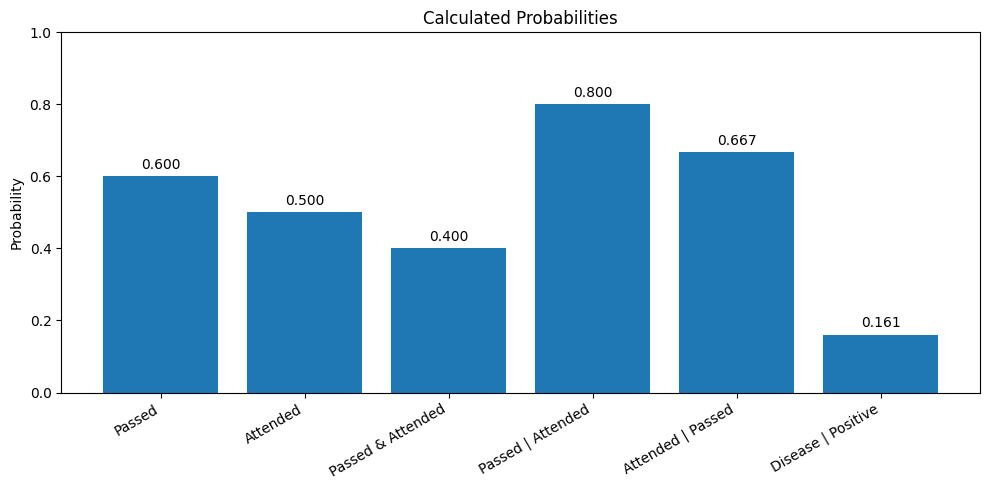

In [8]:
import matplotlib.pyplot as plt
labels=["Passed","Attended","Passed & Attended","Passed | Attended","Attended | Passed","Disease | Positive"]
values=[p_A,p_B,p_inter,p_A_given_B,p_B_given_A,P_D_given_pos]
plt.figure(figsize=(10,5))
bars=plt.bar(labels,values)
plt.ylabel("Probability"); plt.ylim(0,1); plt.title("Calculated Probabilities")
plt.xticks(rotation=30,ha="right")
for bar,value in zip(bars,values): plt.text(bar.get_x()+bar.get_width()/2,value+0.02,f"{value:.3f}",ha="center")
plt.tight_layout(); plt.show()

### Effect of Changing the Prior Disease Probability

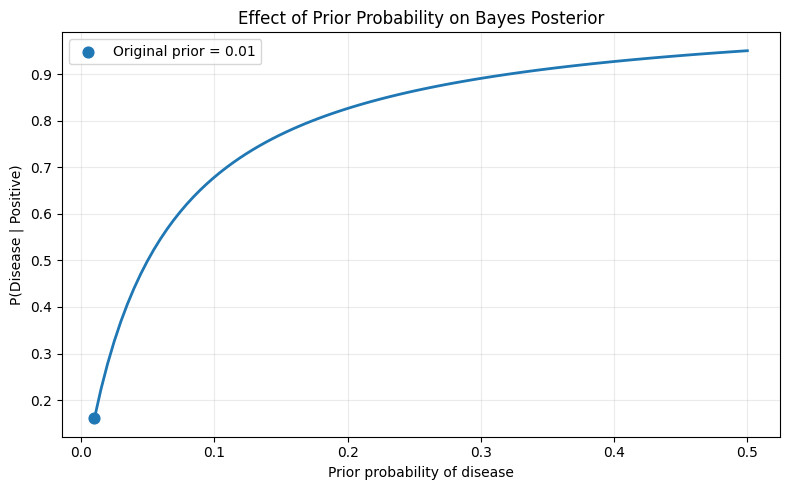

Original prior = 0.01, posterior = 0.161
Modified prior = 0.10, posterior = 0.679


In [9]:
import numpy as np
priors=np.linspace(0.01,0.50,100); posteriors=[]
for prior in priors:
    p_positive=P_pos_given_D*prior+P_pos_given_not_D*(1-prior)
    posteriors.append((P_pos_given_D*prior)/p_positive)
plt.figure(figsize=(8,5)); plt.plot(priors,posteriors,linewidth=2)
plt.scatter([P_D],[P_D_given_pos],s=60,label=f"Original prior = {P_D:.2f}")
plt.xlabel("Prior probability of disease"); plt.ylabel("P(Disease | Positive)")
plt.title("Effect of Prior Probability on Bayes Posterior"); plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()
modified_prior=0.10
modified_positive=P_pos_given_D*modified_prior+P_pos_given_not_D*(1-modified_prior)
modified_posterior=(P_pos_given_D*modified_prior)/modified_positive
print(f"Original prior = {P_D:.2f}, posterior = {P_D_given_pos:.3f}")
print(f"Modified prior = {modified_prior:.2f}, posterior = {modified_posterior:.3f}")

## Overall Observations
1. Propositional logic provides a precise truth-functional representation of simple rules.
2. First-Order Logic allows a general rule about a class of objects to be applied to a particular individual.
3. Probability quantifies uncertainty using observed frequencies.
4. Joint and union probabilities can be calculated directly from event indicators.
5. Conditional probability depends on the event used as the condition.
6. Bayes theorem combines prior belief and evidence to obtain a posterior belief.
7. Visualization makes the effect of changing probabilities easier to interpret.

## Conclusion
The experiment successfully implements propositional reasoning, a simple First-Order Logic inference, event probability, conditional probability, and Bayesian diagnosis using Python. The truth table verifies the propositional implication, the FOL rule derives that Socrates is mortal, the student dataset demonstrates basic probability relationships, and Bayes theorem demonstrates probabilistic updating. The visualization shows how changing an input probability changes the resulting posterior probability.